In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the project folder
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

results_dir = project_dir / "results"

# Load saved experiment results
synthetic_results = pd.read_csv(
    results_dir / "synthetic_results.csv"
)

real_world_results = pd.read_csv(
    results_dir / "real_world_results.csv"
)

print("Both datasets loaded successfully!")
print()
print("Synthetic results:", synthetic_results.shape)
print("Real-world results:", real_world_results.shape)


Both datasets loaded successfully!

Synthetic results: (20, 5)
Real-world results: (19, 5)


In [2]:

# Summarize key results from both datasets
summary = []

experiments = [
    ("Synthetic (Dense Signal)", synthetic_results, 80),
    ("California Housing", real_world_results, 100)
]

for name, data, n_train in experiments:
    # Find the largest observed Least Squares test error
    peak_index = data["least_squares_test_mse"].idxmax()
    peak_row = data.loc[peak_index]

    # Find the result at the largest feature dimension
    final_row = data.loc[data["features"].idxmax()]

    summary.append({
        "Dataset": name,
        "Training Samples": n_train,
        "Peak Dimension": int(peak_row["features"]),
        "Peak Test MSE": peak_row["least_squares_test_mse"],
        "Final Dimension": int(final_row["features"]),
        "Final Test MSE": final_row["least_squares_test_mse"]
    })

summary_df = pd.DataFrame(summary)

print("Double Descent — Dataset Comparison")
display(summary_df.round(4))


Double Descent — Dataset Comparison


,Dataset,Training Samples,Peak Dimension,Peak Test MSE,Final Dimension,Final Test MSE
0,Synthetic (Dense Signal),80,80,19795.5859,500,1.1816
1,California Housing,100,95,74.4046,300,3.2422


In [3]:
summary_df.to_csv(
    results_dir / "final_summary.csv",
    index=False
)

print("Final summary saved successfully!")

Final summary saved successfully!


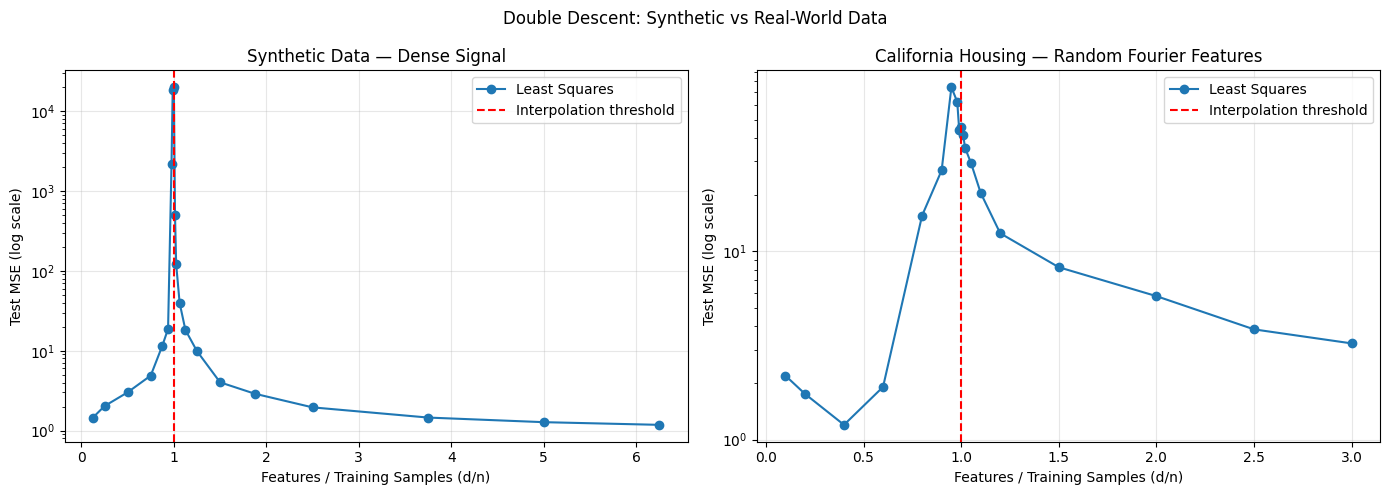

In [4]:

# Final comparison of synthetic and real-world Double Descent
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Synthetic dataset
axes[0].plot(
    synthetic_results["features"] / 80,
    synthetic_results["least_squares_test_mse"],
    marker="o",
    label="Least Squares"
)

axes[0].axvline(1, color="red", linestyle="--",
                label="Interpolation threshold")
axes[0].set_yscale("log")
axes[0].set_title("Synthetic Data — Dense Signal")
axes[0].set_xlabel("Features / Training Samples (d/n)")
axes[0].set_ylabel("Test MSE (log scale)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Real-world dataset
axes[1].plot(
    real_world_results["features"] / 100,
    real_world_results["least_squares_test_mse"],
    marker="o",
    label="Least Squares"
)

axes[1].axvline(1, color="red", linestyle="--",
                label="Interpolation threshold")
axes[1].set_yscale("log")
axes[1].set_title("California Housing — Random Fourier Features")
axes[1].set_xlabel("Features / Training Samples (d/n)")
axes[1].set_ylabel("Test MSE (log scale)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Double Descent: Synthetic vs Real-World Data")
plt.tight_layout()

# Save figure
plt.savefig(
    results_dir / "final_dataset_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [5]:

# Check that the saved experimental results are consistent

datasets = [
    ("Synthetic", synthetic_results, 80),
    ("California Housing", real_world_results, 100)
]

for name, data, n_train in datasets:
    # Verify dimensions and test errors
    assert data["features"].is_unique
    assert (data["features"] > 0).all()
    assert (data["least_squares_test_mse"] >= 0).all()
    assert np.isfinite(data["least_squares_test_mse"]).all()

    # Check whether the interpolation threshold was tested
    assert n_train in data["features"].values

    peak_row = data.loc[data["least_squares_test_mse"].idxmax()]
    final_row = data.loc[data["features"].idxmax()]

    print(f"{name}:")
    print(f"  Interpolation threshold: d = {n_train}")
    print(f"  Observed peak: d = {int(peak_row['features'])}")
    print(f"  Peak test MSE: {peak_row['least_squares_test_mse']:.4f}")
    print(f"  Final test MSE: {final_row['least_squares_test_mse']:.4f}")
    print()

print("All saved-results checks passed!")


Synthetic:
  Interpolation threshold: d = 80
  Observed peak: d = 80
  Peak test MSE: 19795.5859
  Final test MSE: 1.1816

California Housing:
  Interpolation threshold: d = 100
  Observed peak: d = 95
  Peak test MSE: 74.4046
  Final test MSE: 3.2422

All saved-results checks passed!


In [6]:

# Verify our regression implementations
import sys
from sklearn.linear_model import Ridge

src_dir = project_dir / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from linear_models import least_squares, ridge_regression

rng = np.random.default_rng(42)

# Test both underparameterized and overparameterized cases
for n, d in [(80, 20), (80, 120)]:
    X = rng.normal(size=(n, d))
    y = rng.normal(size=n)

    # Least Squares: compare against NumPy reference
    our_ls = least_squares(X, y)
    reference_ls = np.linalg.lstsq(X, y, rcond=None)[0]

    # Ridge: compare against scikit-learn reference
    alpha = 1.0
    our_ridge = ridge_regression(X, y, alpha=alpha)
    reference_ridge = Ridge(
        alpha=alpha,
        fit_intercept=False,
        solver="cholesky"
    ).fit(X, y).coef_

    assert np.allclose(our_ls, reference_ls, atol=1e-7)
    assert np.allclose(our_ridge, reference_ridge, atol=1e-7)

    print(f"n={n}, d={d}: Both algorithms verified!")

print("All implementation checks passed!")


n=80, d=20: Both algorithms verified!
n=80, d=120: Both algorithms verified!
All implementation checks passed!
